# Exercise 4

## 4.1

In [2]:
# importing libraries
import numpy as np
import pandas as pd 

In [3]:
# reading the dataset
df = pd.read_csv('kleibers_law_data.csv', header=None)
df.head()

,0,1,2,3,4,5,6,7,8,9,...,1488,1489,1490,1491,1492,1493,1494,1495,1496,1497
0,1370.0,1250.0,7.4,6.95,8.9,9.6,9.4,9.3,9.35,8.15,...,91.5,73.1,1.465,1.7,1.645,1.638,2.079,1.975,4.12,4.38
1,345000.0,417000.0,3100.0,2898.00,3528.0,3881.0,3830.0,4284.0,3906.00,2386.00,...,23016.0,16527.0,888.700,1126.6,575.400,704.400,1352.900,1439.900,2396.00,2388.00


In [4]:
# log of x and y
log_x = np.log(df.iloc[0,:].values)
log_y = np.log(df.iloc[1,:].values)

In [5]:
# modeling log_y = w0 + w1*log_x
def model(X, w):
    # design matrix
    return X * w[1] + w[0]

# least squares function
least_squares = lambda w: np.sum((log_y - model(log_x, w))**2) / (len(log_y))

## 4.2

In [6]:
import autograd.numpy as np
from autograd import grad 
# gradient descent function - inputs: g (input function), alpha (steplength parameter), max_its (maximum number of iterations), w (initialization)
def gradient_descent(g,alpha,max_its,w):
    # compute gradient module using autograd
    gradient = grad(g)

    # run the gradient descent loop
    weight_history = [w]           # container for weight history
    cost_history = [g(w)]          # container for corresponding cost function history
    for k in range(max_its):
        # evaluate the gradient, store current weights and cost function value
        grad_eval = gradient(w)

        # take gradient descent step
        w = w - alpha*grad_eval
        
        # record weight and cost
        weight_history.append(w)
        cost_history.append(g(w))
    return cost_history, weight_history

In [14]:
# parameter settings
max_its = 1000
alpha = 0.01

# gradient descent call
w0 = np.array([-0.1, 0.1])   # initial guess
cost_history, weight_history = gradient_descent(least_squares, alpha, max_its, w0)


In [15]:
w = weight_history[-1]
w

array([6.81472323, 0.65280987])

## 4.3

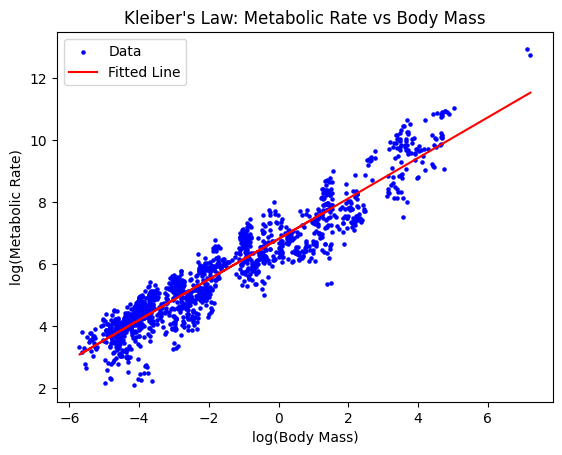

In [9]:
# prediction and plots
w = weight_history[-1]
y_pred = model(log_x, w)

# plotting the results
import matplotlib.pyplot as plt
plt.scatter(log_x, log_y, label='Data', color='blue', s=5)
plt.plot(log_x, y_pred, label='Fitted Line', color='red')
plt.xlabel('log(Body Mass)')
plt.ylabel('log(Metabolic Rate)')
plt.title('Kleiber\'s Law: Metabolic Rate vs Body Mass')
plt.legend()
plt.show()

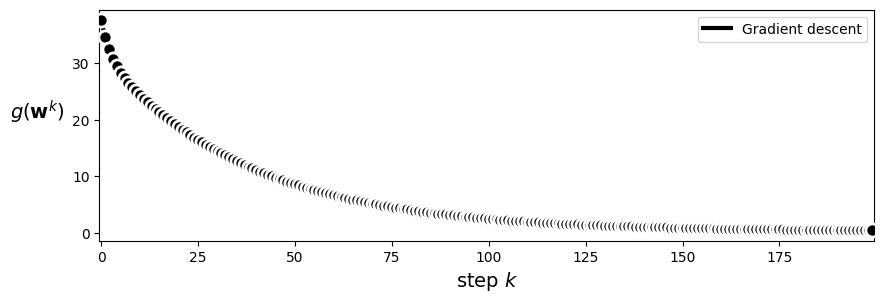

In [10]:
# cost_history plot
from MLRPlotting import static_plotter
# import custom plotting tools
static_plotter = static_plotter.Visualizer()
static_plotter.plot_cost_histories([cost_history[:200]],start=0,points=True,labels=[r'Gradient descent'])

## 4.4

In [11]:
# prediction of the calories required for a 10 Kg animal
x_new = 10.0
log_y_pred = model(np.log(x_new), w)
y_pred = np.exp(log_y_pred) / 4.184  # converting from Joules to calories/day

print("Predicted metabolic rate:", y_pred, "calories/day")

Predicted metabolic rate: 979.0725713986966 calories/day
